# Part 2: The four kinds of clients, and why calling the riskiest ones wastes effort

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

Part 1 showed that churn risk and uplift are barely related among the clients RMs call. This notebook asks what that means in practice.

**In this notebook**

1. The four kinds of client hiding inside a churn list.
2. How they are spread across the 6,000 flagged clients.
3. A simple identity: **expected clients saved = the sum of the uplift of the clients you call.**
4. An experiment: RMs can make 500 calls. How many clients does each targeting rule save?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_series import SERIES_SEED, generate_bank
from uplift_series import plotting as P
from uplift_series.targeting import compare_strategies, random_k, top_k

P.set_style()
pd.set_option("display.float_format", "{:.2f}".format)

df = generate_bank(assignment="random", seed=SERIES_SEED)
flagged = df[df["flagged"] == 1]
print(f"{len(flagged):,} flagged clients")

6,000 flagged clients


## 1. The four kinds of client

Every client falls into one of four groups, depending on how a pricing call changes their chance of leaving:

| Type | If RMs do nothing | If RMs call | Example in institutional banking |
|---|---|---|---|
| **Persuadable** | Likely to leave | Likely to stay | A client paying well above peers, who stays when pricing is fixed |
| **Sure thing** | Stays | Stays | A loyal, well-priced client whose operations run on the bank |
| **Lost cause** | Leaves | Leaves | A client being acquired by a group that banks elsewhere |
| **Sleeping dog** | Stays | More likely to leave | A happy, cheaply priced client who, once pricing comes up, runs an RFP and shops around |

Only persuadables create value. Calls to sure things and lost causes are wasted, and calls to sleeping dogs do harm.

In the synthetic bank, each client's type comes from its true uplift (see `docs/data_spec.md`):

- persuadable: a call cuts churn risk by 5 points or more
- sleeping dog: a call raises churn risk by 2 points or more
- lost cause: little effect, and churn risk of 30% or more
- sure thing: little effect, and lower risk

## 2. Who is on the churn list?

In [2]:
shares = (
    flagged["true_client_type"].value_counts()
    .reindex(P.TYPE_ORDER)
    .rename(index=P.TYPE_LABELS)
)
pd.DataFrame({"clients": shares, "share": shares / shares.sum()})

,clients,share
true_client_type,,
Persuadables,3601,0.60
Sure things,1109,0.18
Lost causes,752,0.13
Sleeping dogs,538,0.09


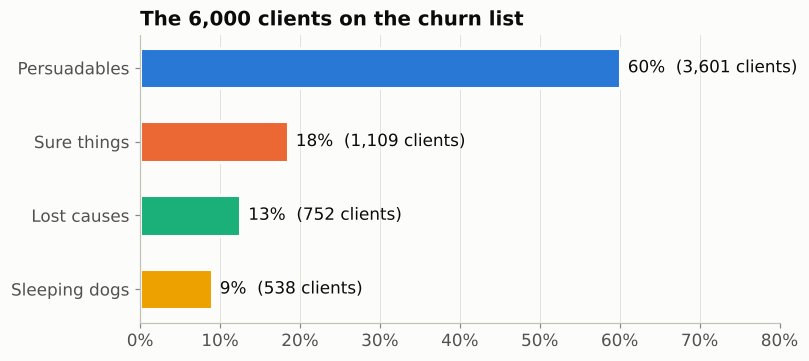

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
order = P.TYPE_ORDER[::-1]
values = flagged["true_client_type"].value_counts().reindex(order)
share = values / values.sum()
bars = ax.barh([P.TYPE_LABELS[t] for t in order], share,
               color=[P.TYPE_COLORS[t] for t in order], height=0.55,
               edgecolor=P.SURFACE, linewidth=2)
for b, n, s in zip(bars, values, share):
    ax.text(b.get_width() + 0.01, b.get_y() + b.get_height() / 2,
            f"{s:.0%}  ({n:,} clients)", va="center", color=P.INK, fontsize=11)
ax.set_xlim(0, 0.8)
P.percent_axis(ax, "x")
ax.grid(axis="y", visible=False)
ax.set_title("The 6,000 clients on the churn list")
P.save(fig, "02_client_types")
plt.show()

## 3. Where each type sits

Each panel below plots every flagged client by churn risk (across) and uplift (up), and highlights one type.

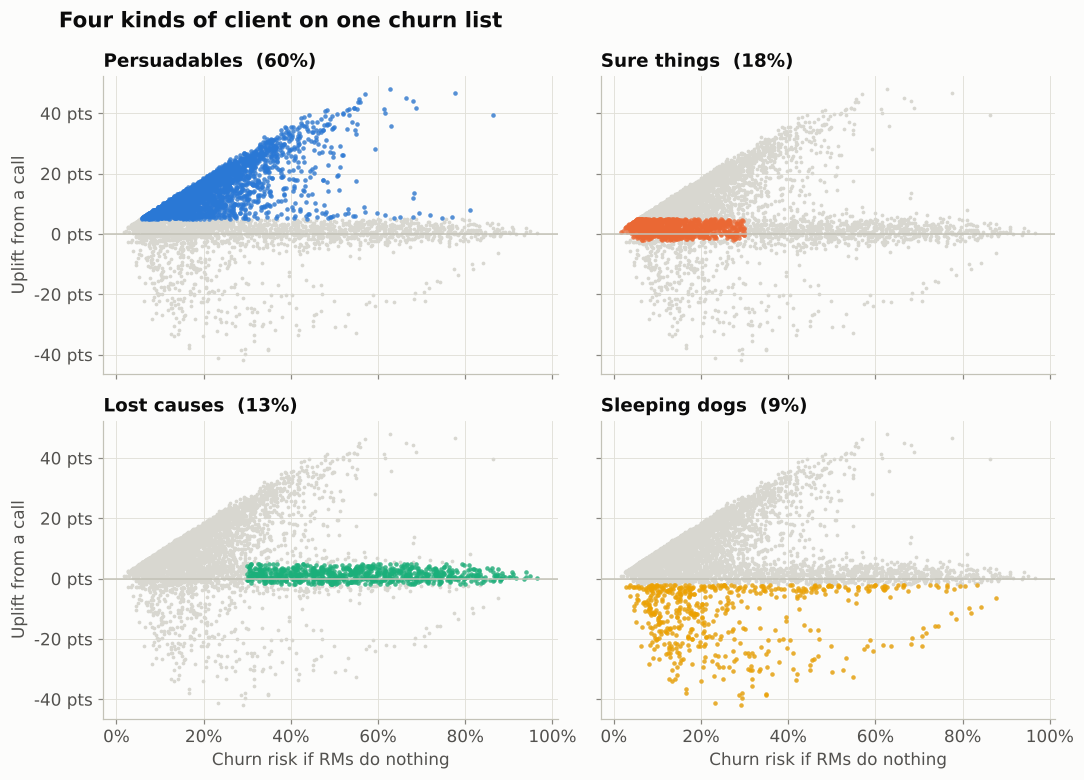

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2), sharex=True, sharey=True)
x_all = flagged["true_p_churn_no_action"]
y_all = flagged["true_uplift"]
for ax, t in zip(axes.flat, P.TYPE_ORDER):
    ax.scatter(x_all, y_all, s=6, color=P.BACKGROUND_POINTS, linewidths=0)
    sub = flagged[flagged["true_client_type"] == t]
    ax.scatter(sub["true_p_churn_no_action"], sub["true_uplift"], s=9,
               color=P.TYPE_COLORS[t], alpha=0.75, linewidths=0)
    ax.axhline(0, color=P.BASELINE, linewidth=1)
    ax.set_title(f"{P.TYPE_LABELS[t]}  ({len(sub) / len(flagged):.0%})", fontsize=12)
    P.percent_axis(ax, "x")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v * 100:.0f} pts")
for ax in axes[1]:
    ax.set_xlabel("Churn risk if RMs do nothing")
for ax in axes[:, 0]:
    ax.set_ylabel("Uplift from a call")
fig.suptitle("Four kinds of client on one churn list", x=0.06, ha="left",
             fontsize=14, fontweight="bold")
fig.tight_layout()
P.save(fig, "02_four_types")
plt.show()

Notice where the lost causes sit: **far to the right**. They are the riskiest clients on the list, and a call does almost nothing for them. A rule that says "call the riskiest first" walks straight into them.

## 4. The identity that decides who to call

A client's uplift is the drop in their probability of leaving caused by a call. So if RMs call a set of clients, the number of clients the calls keep, on average, is simply the **sum of those clients' uplifts**.

A tiny example with four clients:

| Client | Risk if no call | Risk with call | Uplift |
|---|---|---|---|
| A (lost cause) | 80% | 78% | 0.02 |
| B (persuadable) | 40% | 15% | 0.25 |
| C (sure thing) | 5% | 5% | 0.00 |
| D (sleeping dog) | 10% | 20% | −0.10 |

With one call, ranking by risk picks A and saves 0.02 of a client. Ranking by uplift picks B and saves 0.25. Calling all four saves 0.17, less than calling B alone, because D is pushed out.

To save the most clients with a fixed number of calls, **call the clients with the highest uplift**.

## 5. The 500-call experiment

RMs have time for 500 pricing negotiations this cycle. Compare three ways to choose them from the 6,000 flagged clients:

- **Random:** any 500 flagged clients.
- **Riskiest first:** the 500 with the highest churn-model score. This is what most banks do.
- **Highest uplift first:** the 500 with the highest *true* uplift. Impossible in real life, because nobody knows true uplift, but it shows the ceiling an uplift model is aiming for.

In [5]:
K = 500
strategies = {
    "Random": random_k(flagged, K, seed=1),
    "Riskiest first": top_k(flagged, "churn_score", K),
    "Highest uplift first": top_k(flagged, "true_uplift", K),
}
results = compare_strategies(flagged, K, strategies)
results[["expected_saved", "expected_pushed_out", "avg_churn_risk", "avg_uplift",
         "persuadables", "sure_things", "lost_causes", "sleeping_dogs"]]

,expected_saved,expected_pushed_out,avg_churn_risk,avg_uplift,persuadables,sure_things,lost_causes,sleeping_dogs
strategy,,,,,,,,
Random,35.21,8.02,0.23,0.07,288,96,54,62
Riskiest first,9.93,5.67,0.63,0.02,44,10,390,56
Highest uplift first,135.83,0.00,0.35,0.27,500,0,0,0


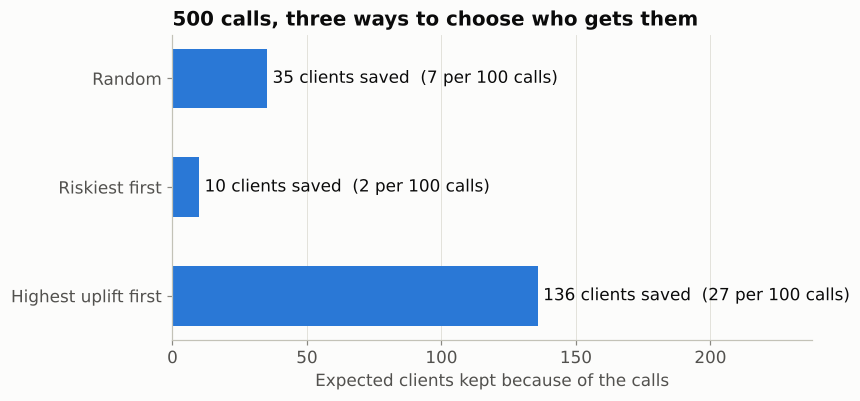

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
names = list(results.index)[::-1]
saved = results.loc[names, "expected_saved"]
bars = ax.barh(names, saved, color=P.BLUE, height=0.55)
for b, v in zip(bars, saved):
    ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2,
            f"{v:.0f} clients saved  ({v / K * 100:.0f} per 100 calls)",
            va="center", color=P.INK, fontsize=11)
ax.set_xlim(0, saved.max() * 1.75)
ax.set_xlabel("Expected clients kept because of the calls")
ax.grid(axis="y", visible=False)
ax.set_title("500 calls, three ways to choose who gets them")
P.save(fig, "02_clients_saved")
plt.show()

Calling the riskiest clients first saves fewer clients than picking at random. Why? Look at who each rule actually calls.

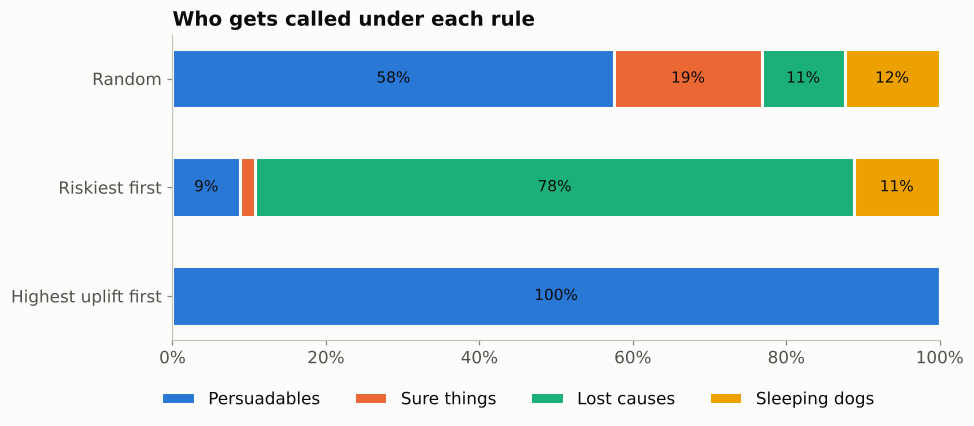

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
names = list(results.index)[::-1]
cols = {"persuadable": "persuadables", "sure_thing": "sure_things",
        "lost_cause": "lost_causes", "sleeping_dog": "sleeping_dogs"}
left = np.zeros(len(names))
for t in P.TYPE_ORDER:
    counts = results.loc[names, cols[t]].to_numpy()
    share = counts / K
    ax.barh(names, share, left=left, color=P.TYPE_COLORS[t], height=0.55,
            edgecolor=P.SURFACE, linewidth=2, label=P.TYPE_LABELS[t])
    for i, (l, s) in enumerate(zip(left, share)):
        if s >= 0.07:
            ax.text(l + s / 2, i, f"{s:.0%}", ha="center", va="center", color=P.INK, fontsize=10)
    left += share
P.percent_axis(ax, "x")
ax.set_xlim(0, 1)
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=4)
ax.set_title("Who gets called under each rule")
P.save(fig, "02_who_gets_called")
plt.show()

The riskiest-first list is dominated by **lost causes**: clients who are leaving whatever RMs do. It also carries sleeping dogs, who are pushed out by the call. The uplift-first list is entirely persuadables.

## Takeaways

- A churn list mixes four kinds of client, and only **persuadables** gain from a call.
- The riskiest clients are disproportionately **lost causes**, so "call the riskiest first" can do worse than choosing at random.
- **Expected clients saved = the sum of the uplift of the clients you call**, so the best list ranks clients by uplift.
- The catch: nobody can see true uplift. The rest of the series is about estimating it from data, checking the estimate, and correcting it when the data is biased.

**Next, Part 3:** the data an uplift model needs: treated and control clients, a start date, and the leakage trap that makes models look perfect and fail in practice.